# Swissquote BBO — weekend pause

**Decision question:** should the ingestion pipeline stop fetching on weekends (or during a weekend pause window), or keep consuming continuously?

This notebook measures when quotes thin out / go stale over Fri→Mon, whether residual weekend inserts carry new information, and proposes a concrete pause schedule.

**Scope:** `swissquote.bbo` ticks. Primary clock is `ingestion_time` (when the pipeline wrote a row). Quote `ts` and `quote_age_ms` diagnose staleness. FX spot typically closes near New York Friday 17:00 and reopens Sunday 17:00 local — in July that is **21:00 UTC** both sides (EDT).

**Prerequisites:** same as `01_bbo_overview.ipynb` (`~/.env`, venv with `pip install -e "../python[databases]"` and `pip install -r requirements.txt`).

Related: `01_bbo_overview.ipynb`, `02_spreads_eda.ipynb`. Project note: quote `ts` can be stale on weekends while `ingestion_time` still advances.

In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from swissquote.clickhouse import ClickHouseConfig, create_client

from ch_utils import QUERY_SETTINGS, load_bbo_df, table_overview

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

cfg = ClickHouseConfig.from_env()
client = create_client(cfg)
print(f"Connected to {cfg.host}:{cfg.port} as {cfg.user}")

Connected to 127.0.0.1:9000 as default


## Session / timezone conventions

| Concept | Convention used here |
|---|---|
| All timestamps | UTC (`DateTime64(3, 'UTC')` on `ts` and `ingestion_time`) |
| ClickHouse `toDayOfWeek` | 1 = Monday … 7 = Sunday |
| FX weekend (NY) | Fri 17:00 → Sun 17:00 America/New_York |
| Candidate pause (summer / EDT) | **Fri 21:00 UTC → Sun 21:00 UTC** |
| Candidate pause (winter / EST) | Fri 22:00 UTC → Sun 22:00 UTC |

We treat a row as inside the **candidate pause** when `ingestion_time` falls in `[Fri 21:00, Sun 21:00)` UTC. That window is validated empirically below; adjust for EST if re-running outside daylight-saving months.

Analysis prefers **ClickHouse aggregations** over loading full tick history (~100M+ rows). Sample tick loads via `load_bbo_df` are used only for mid-staleness spot checks.

In [2]:
# Candidate pause in UTC hour-of-week space (Mon=0 … Sun=6 for pandas; CH dow 1..7).
PAUSE_FRI_HOUR_UTC = 21  # inclusive start on Friday
PAUSE_SUN_HOUR_UTC = 21  # exclusive end on Sunday (resume from this hour)

PAUSE_SQL = f"""
    (toDayOfWeek(ingestion_time) = 5 AND toHour(ingestion_time) >= {PAUSE_FRI_HOUR_UTC})
    OR toDayOfWeek(ingestion_time) = 6
    OR (toDayOfWeek(ingestion_time) = 7 AND toHour(ingestion_time) < {PAUSE_SUN_HOUR_UTC})
"""

DOW_LABELS = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}


def query_df(sql: str, params: dict | None = None, columns: list[str] | None = None) -> pd.DataFrame:
    rows = client.execute(sql, params or {}, settings=QUERY_SETTINGS)
    if columns is None:
        return pd.DataFrame(rows)
    return pd.DataFrame(rows, columns=columns)

## Coverage

Use as much history as ClickHouse holds so multiple weekends are visible when available.

In [3]:
overview = table_overview(client)
print(f"Rows (FINAL): {overview['row_count']:,}")
print(f"Ingestion range: {overview['ingestion_min']} → {overview['ingestion_max']}")
print(f"Symbols: {len(overview['symbol_counts'])}")

span = pd.Timestamp(overview["ingestion_max"]) - pd.Timestamp(overview["ingestion_min"])
print(f"Span: {span} (~{span.days / 7:.1f} weeks)")

Rows (FINAL): 126,625,443
Ingestion range: 2026-07-05 21:05:13.290000+00:00 → 2026-07-23 22:41:20.201000+00:00
Symbols: 117
Span: 18 days 01:36:06.911000 (~2.6 weeks)


## 1. Update rate by hour-of-week

Ingestion rows/hour averaged across the full history, keyed by ClickHouse day-of-week + hour (UTC). A clean FX close shows as a cliff after Friday evening and a ramp on Sunday evening.

,dow_label,hour,rows,symbols,streams,p50_age_ms,avg_age_ms
117,Fri,21,96,11,84,1359853.0,1.358256e+06
118,Fri,22,92,11,80,5824452.0,5.596163e+06
119,Fri,23,76,12,76,9313167.0,9.234007e+06
120,Sat,0,41,8,41,11481293.0,1.177185e+07
121,Sat,1,51,6,51,15930244.0,1.619505e+07
122,Sat,2,78,11,78,19526021.0,1.987163e+07
123,Sat,3,45,9,45,23427553.0,2.353928e+07
124,Sat,4,64,10,64,26571783.0,2.662499e+07
125,Sat,5,51,10,51,30700378.0,3.063759e+07
126,Sat,6,48,6,48,34341834.0,3.448900e+07


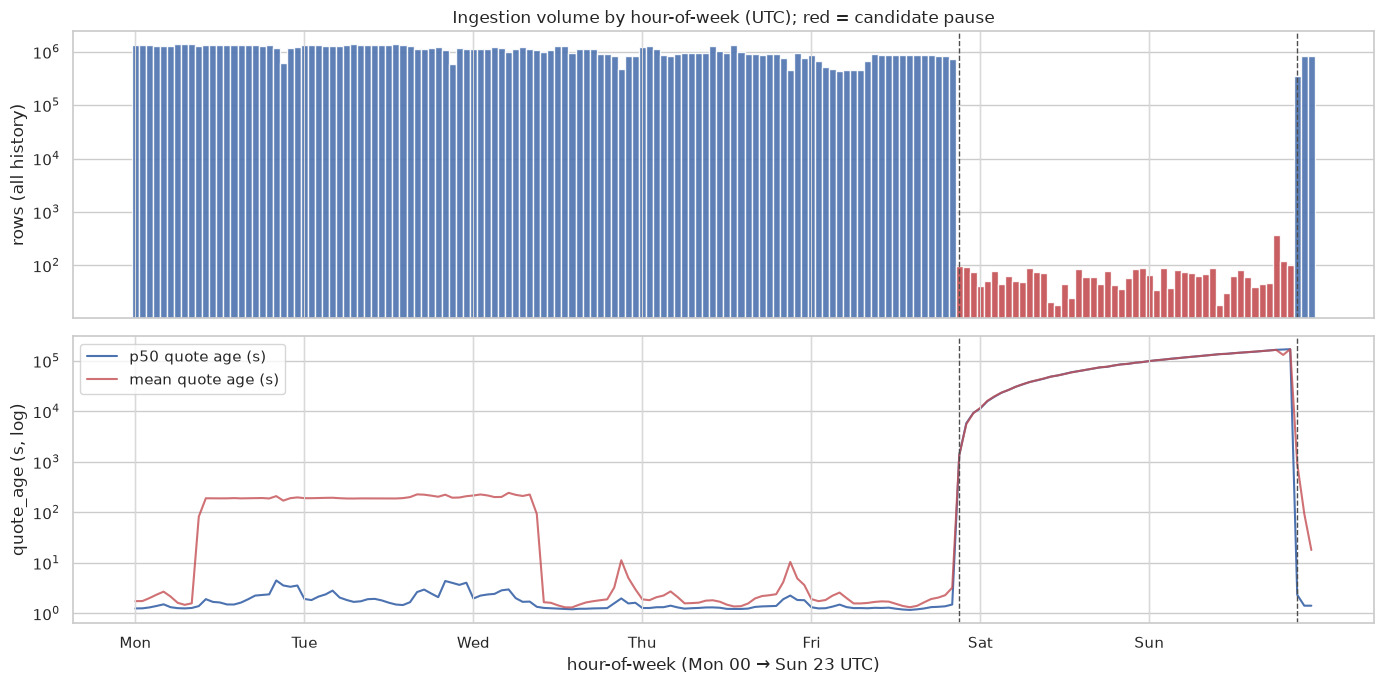

In [4]:
how = query_df(
    """
    SELECT
      toDayOfWeek(ingestion_time) AS dow,
      toHour(ingestion_time) AS hour,
      count() AS rows,
      uniqExact(symbol) AS symbols,
      uniqExact((symbol, platform, server, spread_profile)) AS streams,
      avg(quote_age_ms) AS avg_age_ms,
      quantile(0.5)(quote_age_ms) AS p50_age_ms,
      quantile(0.95)(quote_age_ms) AS p95_age_ms
    FROM swissquote.bbo
    GROUP BY dow, hour
    ORDER BY dow, hour
    """,
    columns=[
        "dow", "hour", "rows", "symbols", "streams",
        "avg_age_ms", "p50_age_ms", "p95_age_ms",
    ],
)
how["dow_label"] = how["dow"].map(DOW_LABELS)
how["how_index"] = (how["dow"] - 1) * 24 + how["hour"]  # Mon 00 = 0 … Sun 23 = 167
how["in_pause"] = (
    ((how["dow"] == 5) & (how["hour"] >= PAUSE_FRI_HOUR_UTC))
    | (how["dow"] == 6)
    | ((how["dow"] == 7) & (how["hour"] < PAUSE_SUN_HOUR_UTC))
)
display(how.loc[how["in_pause"], ["dow_label", "hour", "rows", "symbols", "streams", "p50_age_ms", "avg_age_ms"]].head(20))

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].bar(how["how_index"], how["rows"], width=1.0, color=np.where(how["in_pause"], "#c44e52", "#4c72b0"), alpha=0.9)
axes[0].set_ylabel("rows (all history)")
axes[0].set_title("Ingestion volume by hour-of-week (UTC); red = candidate pause")
axes[0].set_yscale("log")

axes[1].plot(how["how_index"], how["p50_age_ms"] / 1000, label="p50 quote age (s)", color="#4c72b0")
axes[1].plot(how["how_index"], how["avg_age_ms"] / 1000, label="mean quote age (s)", color="#c44e52", alpha=0.8)
axes[1].set_yscale("log")
axes[1].set_ylabel("quote_age (s, log)")
axes[1].set_xlabel("hour-of-week (Mon 00 → Sun 23 UTC)")
axes[1].legend()
for ax in axes:
    for d in range(1, 8):
        ax.axvline((d - 1) * 24, color="0.85", lw=0.8)
    ax.axvline((5 - 1) * 24 + PAUSE_FRI_HOUR_UTC, color="0.3", ls="--", lw=1)
    ax.axvline((7 - 1) * 24 + PAUSE_SUN_HOUR_UTC, color="0.3", ls="--", lw=1)
axes[1].set_xticks([(i - 1) * 24 for i in range(1, 8)])
axes[1].set_xticklabels([DOW_LABELS[i] for i in range(1, 8)])
fig.tight_layout()
plt.show()

## 2. Fri→Mon timeline (per weekend)

Hourly ingestion for each available Friday noon → Monday noon window. Confirms whether the cliff / reopen is stable across weekends.

,week_start,last_busy_fri_hour,first_busy_sun_hour,pause_rows,week_rows,pause_frac
0,2026-06-29,1970-01-01 00:00:00+00:00,1970-01-01 00:00:00+00:00,0,3,0.000000
1,2026-07-06,2026-07-10 20:00:00+00:00,2026-07-12 21:00:00+00:00,1417,51690318,0.000027
2,2026-07-13,2026-07-17 20:00:00+00:00,2026-07-19 21:00:00+00:00,1871,47581308,0.000039
3,2026-07-20,1970-01-01 00:00:00+00:00,1970-01-01 00:00:00+00:00,0,27354897,0.000000


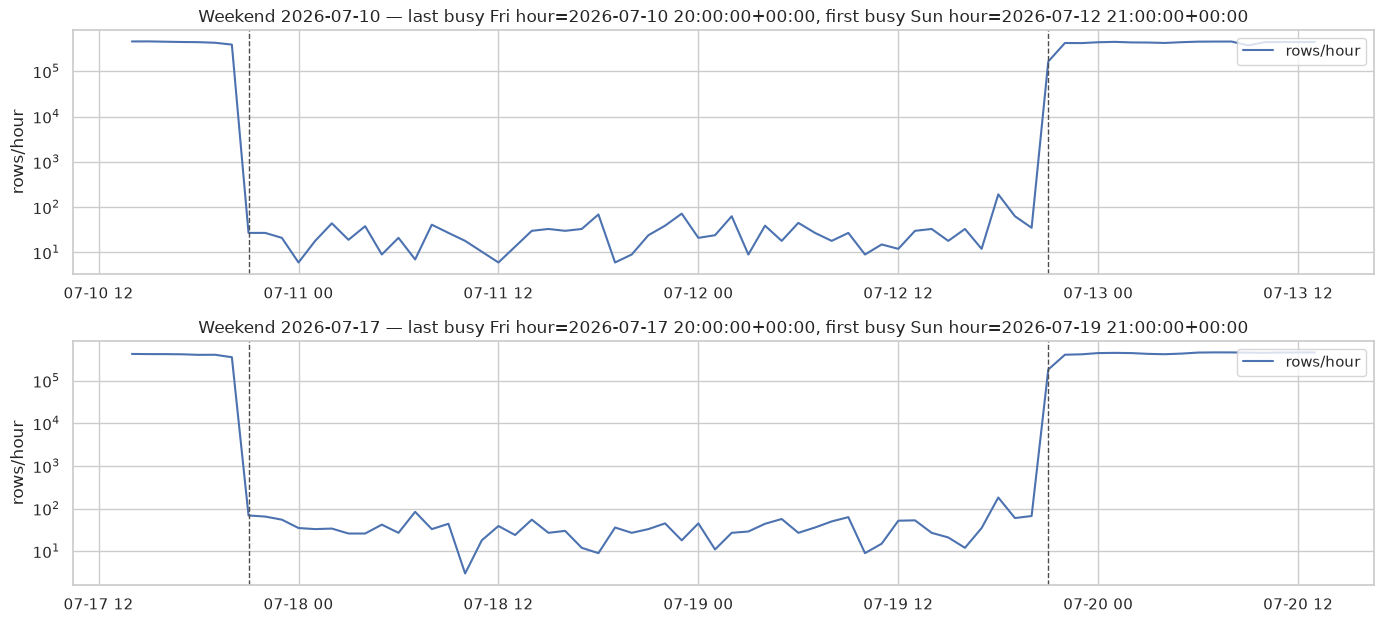

In [5]:
weekends = query_df(
    """
    WITH hourly AS (
      SELECT
        toStartOfHour(ingestion_time) AS h,
        toDayOfWeek(ingestion_time) AS dow,
        count() AS n,
        uniqExact(symbol) AS symbols,
        uniqExact((symbol, platform, server, spread_profile)) AS streams,
        avg(quote_age_ms) AS avg_age_ms,
        quantile(0.5)(quote_age_ms) AS p50_age_ms,
        uniqExact(ts) AS unique_ts,
        uniqExact((bid_price + ask_price) * 0.5) AS unique_mids
      FROM swissquote.bbo
      GROUP BY h, dow
    )
    SELECT
      toStartOfWeek(h, 1) AS week_start,
      maxIf(h, dow = 5 AND n >= 10000) AS last_busy_fri_hour,
      minIf(h, dow = 7 AND n >= 10000) AS first_busy_sun_hour,
      sumIf(n, (dow = 5 AND toHour(h) >= 21) OR dow = 6 OR (dow = 7 AND toHour(h) < 21)) AS pause_rows,
      sum(n) AS week_rows
    FROM hourly
    GROUP BY week_start
    ORDER BY week_start
    """,
    columns=["week_start", "last_busy_fri_hour", "first_busy_sun_hour", "pause_rows", "week_rows"],
)
weekends["pause_frac"] = weekends["pause_rows"] / weekends["week_rows"].replace(0, np.nan)
display(weekends)

# Plot each weekend that has a real busy Friday close
busy = weekends.dropna(subset=["last_busy_fri_hour"]).copy()
busy = busy[busy["last_busy_fri_hour"].astype(str) > "2000-01-01"]

fig, axes = plt.subplots(len(busy) or 1, 1, figsize=(14, 3.2 * max(len(busy), 1)), sharex=False)
if len(busy) <= 1:
    axes = [axes]

for ax, (_, wrow) in zip(axes, busy.iterrows()):
    fri = pd.Timestamp(wrow["last_busy_fri_hour"]).tz_convert("UTC").normalize()  # Friday date from busy hour
    # last_busy is typically Fri 20:00 → weekend starts that calendar Friday
    fri_date = pd.Timestamp(wrow["last_busy_fri_hour"]).tz_convert("UTC").floor("D")
    start = fri_date + pd.Timedelta(hours=12)
    end = fri_date + pd.Timedelta(days=3, hours=12)  # Mon noon
    hourly = query_df(
        """
        SELECT
          toStartOfHour(ingestion_time) AS h,
          count() AS n,
          avg(quote_age_ms) AS avg_age_ms,
          quantile(0.5)(quote_age_ms) AS p50_age_ms
        FROM swissquote.bbo
        WHERE ingestion_time >= %(start)s AND ingestion_time < %(end)s
        GROUP BY h
        ORDER BY h
        """,
        {"start": start.to_pydatetime(), "end": end.to_pydatetime()},
        columns=["h", "n", "avg_age_ms", "p50_age_ms"],
    )
    if hourly.empty:
        ax.set_title(f"{fri_date.date()} — no data")
        continue
    ax.semilogy(hourly["h"], hourly["n"], color="#4c72b0", label="rows/hour")
    ax.axvline(fri_date + pd.Timedelta(hours=PAUSE_FRI_HOUR_UTC), color="0.3", ls="--", lw=1)
    ax.axvline(fri_date + pd.Timedelta(days=2, hours=PAUSE_SUN_HOUR_UTC), color="0.3", ls="--", lw=1)
    ax.set_ylabel("rows/hour")
    ax.set_title(
        f"Weekend {fri_date.date()} — last busy Fri hour={wrow['last_busy_fri_hour']}, "
        f"first busy Sun hour={wrow['first_busy_sun_hour']}"
    )
    ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

## 3. Residual / stale quotes during the pause

If the API keeps returning Friday-close quotes, we still insert a trickle of rows with frozen `ts`, climbing `quote_age_ms`, and few unique mids. That is storage + compute cost without market information.

In [6]:
pause_summary = query_df(
    f"""
    SELECT
      count() AS pause_rows,
      (SELECT count() FROM swissquote.bbo) AS total_rows,
      uniqExact(symbol) AS symbols,
      uniqExact((symbol, platform, server, spread_profile)) AS streams,
      uniqExact(ts) AS unique_ts,
      uniqExact((bid_price + ask_price) * 0.5) AS unique_mids,
      min(ts) AS min_ts,
      max(ts) AS max_ts,
      min(ingestion_time) AS min_ingestion,
      max(ingestion_time) AS max_ingestion,
      avg(quote_age_ms) AS avg_age_ms,
      quantile(0.5)(quote_age_ms) AS p50_age_ms,
      quantile(0.95)(quote_age_ms) AS p95_age_ms
    FROM swissquote.bbo
    WHERE {PAUSE_SQL}
    """,
    columns=[
        "pause_rows", "total_rows", "symbols", "streams", "unique_ts", "unique_mids",
        "min_ts", "max_ts", "min_ingestion", "max_ingestion",
        "avg_age_ms", "p50_age_ms", "p95_age_ms",
    ],
).iloc[0]

print(
    f"Pause rows: {pause_summary['pause_rows']:,} / {pause_summary['total_rows']:,} "
    f"({100 * pause_summary['pause_rows'] / pause_summary['total_rows']:.4f}%)"
)
print(f"Unique quote ts:  {pause_summary['unique_ts']:,}")
print(f"Unique mids:      {pause_summary['unique_mids']:,}")
print(f"Streams touched:  {pause_summary['streams']:,} across {pause_summary['symbols']} symbols")
print(f"Quote ts range:   {pause_summary['min_ts']} → {pause_summary['max_ts']}")
print(f"Ingestion range:  {pause_summary['min_ingestion']} → {pause_summary['max_ingestion']}")
print(
    f"Age p50/mean/p95: {pause_summary['p50_age_ms']/3.6e6:.1f}h / "
    f"{pause_summary['avg_age_ms']/3.6e6:.1f}h / {pause_summary['p95_age_ms']/3.6e6:.1f}h"
)

rates = query_df(
    f"""
    SELECT
      avgIf(n, period = 'active') AS avg_active_hour,
      avgIf(n, period = 'pause') AS avg_pause_hour
    FROM (
      SELECT
        toStartOfHour(ingestion_time) AS h,
        count() AS n,
        if({PAUSE_SQL}, 'pause', 'active') AS period
      FROM swissquote.bbo
      GROUP BY h, period
    )
    """,
    columns=["avg_active_hour", "avg_pause_hour"],
).iloc[0]
ratio = rates["avg_active_hour"] / max(rates["avg_pause_hour"], 1e-9)
print(
    f"\nAvg rows/hour — active: {rates['avg_active_hour']:,.0f}, "
    f"pause: {rates['avg_pause_hour']:,.1f}  (~{ratio:,.0f}× lower)"
)

Pause rows: 3,288 / 126,626,526 (0.0026%)
Unique quote ts:  23
Unique mids:      327
Streams touched:  841 across 96 symbols
Quote ts range:   2026-07-10 20:23:47.894000+00:00 → 2026-07-17 21:00:00.081000+00:00
Ingestion range:  2026-07-10 21:02:24.374000+00:00 → 2026-07-19 20:36:52.439000+00:00
Age p50/mean/p95: 26.8h / 26.0h / 46.6h



Avg rows/hour — active: 379,113, pause: 35.0  (~10,838× lower)


In [7]:
by_platform = query_df(
    f"""
    SELECT
      platform,
      count() AS pause_rows,
      uniqExact(symbol) AS symbols,
      uniqExact(ts) AS unique_ts,
      uniqExact((bid_price + ask_price) * 0.5) AS unique_mids,
      avg(quote_age_ms) AS avg_age_ms
    FROM swissquote.bbo
    WHERE {PAUSE_SQL}
    GROUP BY platform
    ORDER BY pause_rows DESC
    """,
    columns=["platform", "pause_rows", "symbols", "unique_ts", "unique_mids", "avg_age_ms"],
)
print("Pause residual by platform")
display(by_platform)

by_stream = query_df(
    f"""
    SELECT
      symbol, platform, server, spread_profile,
      count() AS n,
      min(ingestion_time) AS first_ing,
      max(ingestion_time) AS last_ing,
      min(ts) AS min_ts,
      max(ts) AS max_ts,
      uniqExact(ts) AS unique_ts,
      uniqExact((bid_price + ask_price) * 0.5) AS unique_mids,
      avg(quote_age_ms) AS avg_age_ms
    FROM swissquote.bbo
    WHERE {PAUSE_SQL}
    GROUP BY symbol, platform, server, spread_profile
    ORDER BY n DESC
    LIMIT 25
    """,
    columns=[
        "symbol", "platform", "server", "spread_profile", "n",
        "first_ing", "last_ing", "min_ts", "max_ts",
        "unique_ts", "unique_mids", "avg_age_ms",
    ],
)
print("Top residual streams (by row count)")
display(by_stream)

Pause residual by platform


,platform,pause_rows,symbols,unique_ts,unique_mids,avg_age_ms
0,SwissquoteCapitalMarkets,1122,94,21,274,9.197879e+07
1,SwissquoteLtd,1113,94,23,264,9.431817e+07
2,AT,1053,92,21,222,9.486557e+07


Top residual streams (by row count)


,symbol,platform,server,spread_profile,n,first_ing,last_ing,min_ts,max_ts,unique_ts,unique_mids,avg_age_ms
0,AUD/NZD,SwissquoteCapitalMarkets,Live7,elite,10,2026-07-11 01:23:41.042000+00:00,2026-07-19 18:59:59.402000+00:00,2026-07-10 21:00:00.051000+00:00,2026-07-17 21:00:00.081000+00:00,10,7,1.042419e+08
1,NZD/JPY,SwissquoteLtd,Live5,premium,10,2026-07-11 18:34:23.590000+00:00,2026-07-19 18:59:59.402000+00:00,2026-07-10 21:00:00.050000+00:00,2026-07-17 21:00:00.081000+00:00,10,8,9.481813e+07
2,AUD/NZD,SwissquoteLtd,Live5,prime,10,2026-07-11 01:23:41.042000+00:00,2026-07-19 18:59:59.402000+00:00,2026-07-10 21:00:00.051000+00:00,2026-07-17 21:00:00.081000+00:00,10,9,1.042419e+08
3,AUD/NZD,SwissquoteCapitalMarkets,Live7,premium,10,2026-07-11 01:23:41.042000+00:00,2026-07-19 18:59:59.402000+00:00,2026-07-10 21:00:00.051000+00:00,2026-07-17 21:00:00.081000+00:00,10,7,1.042419e+08
4,AUD/NZD,SwissquoteCapitalMarkets,Live7,prime,10,2026-07-11 01:23:41.042000+00:00,2026-07-19 18:59:59.402000+00:00,2026-07-10 21:00:00.051000+00:00,2026-07-17 21:00:00.081000+00:00,10,7,1.042419e+08
5,AUD/NZD,AT,AT,premium,10,2026-07-11 01:23:41.042000+00:00,2026-07-19 18:59:59.402000+00:00,2026-07-10 21:00:00.051000+00:00,2026-07-17 21:00:00.081000+00:00,10,9,1.042419e+08
6,NZD/JPY,SwissquoteLtd,Live5,prime,10,2026-07-11 18:34:23.590000+00:00,2026-07-19 18:59:59.402000+00:00,2026-07-10 21:00:00.050000+00:00,2026-07-17 21:00:00.081000+00:00,10,9,9.481813e+07
7,AUD/NZD,AT,AT,prime,10,2026-07-11 01:23:41.042000+00:00,2026-07-19 18:59:59.402000+00:00,2026-07-10 21:00:00.051000+00:00,2026-07-17 21:00:00.081000+00:00,10,9,1.042419e+08
8,NZD/JPY,SwissquoteLtd,Live5,elite,10,2026-07-11 18:34:23.590000+00:00,2026-07-19 18:59:59.402000+00:00,2026-07-10 21:00:00.050000+00:00,2026-07-17 21:00:00.081000+00:00,10,8,9.481813e+07
9,AUD/NZD,AT,AT,standard,10,2026-07-11 01:23:41.042000+00:00,2026-07-19 18:59:59.402000+00:00,2026-07-10 21:00:00.051000+00:00,2026-07-17 21:00:00.081000+00:00,10,9,1.042419e+08


## 4. Mid / ts staleness spot check

Load residual pause ticks (small) and a weekday control window for one liquid symbol. During the pause we expect frozen or near-frozen mids and ages measured in hours–days.

Pause ticks for ('EUR/USD', 'XAU/USD', 'GBP/JPY'): 41


,n,unique_ts,unique_mids,age_p50_h,age_max_h
symbol,,,,,
EUR/USD,27,3,9,9.44,47.15
GBP/JPY,9,1,2,45.56,45.56
XAU/USD,5,3,2,27.72,47.22



Weekday control EUR/USD 2026-07-17 18:00:00+00:00 → 2026-07-17 20:00:00+00:00: 3,906 rows
  unique ts=436, unique mid=105, p50 age=2329 ms


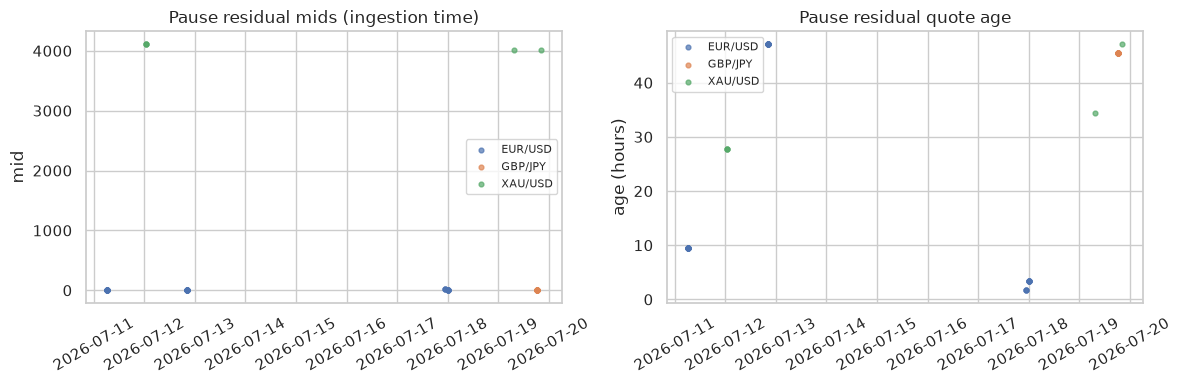

In [8]:
SPOT_SYMBOLS = ("EUR/USD", "XAU/USD", "GBP/JPY")

pause_ticks = query_df(
    f"""
    SELECT
      ts, symbol, platform, server, spread_profile,
      bid_price, ask_price, ingestion_time,
      mid, spread_bps, quote_age_ms
    FROM swissquote.bbo
    PREWHERE symbol IN %(symbols)s
    WHERE {PAUSE_SQL}
    ORDER BY ingestion_time
    """,
    {"symbols": list(SPOT_SYMBOLS)},
    columns=[
        "ts", "symbol", "platform", "server", "spread_profile",
        "bid_price", "ask_price", "ingestion_time",
        "mid", "spread_bps", "quote_age_ms",
    ],
)
print(f"Pause ticks for {SPOT_SYMBOLS}: {len(pause_ticks):,}")
if not pause_ticks.empty:
    display(
        pause_ticks.groupby("symbol")
        .agg(
            n=("ts", "size"),
            unique_ts=("ts", "nunique"),
            unique_mids=("mid", "nunique"),
            age_p50_h=("quote_age_ms", lambda s: s.median() / 3.6e6),
            age_max_h=("quote_age_ms", lambda s: s.max() / 3.6e6),
        )
        .round(2)
    )

# Weekday control: last ~6h of a busy Friday afternoon (via helper)
ing_max = pd.Timestamp(overview["ingestion_max"]).tz_convert("UTC")
# Prefer a Friday before the latest weekend if possible
control_end = ing_max.floor("D")
while control_end.dayofweek != 4:  # Friday
    control_end -= pd.Timedelta(days=1)
control_end = control_end + pd.Timedelta(hours=20)  # Fri 20:00 UTC
control_start = control_end - pd.Timedelta(hours=2)

ctrl = load_bbo_df(
    client,
    symbol=SPOT_SYMBOLS[0],
    ts_start=control_start,
    ts_end=control_end,
    hours=None,
    limit=None,
)
print(f"\nWeekday control {SPOT_SYMBOLS[0]} {control_start} → {control_end}: {len(ctrl):,} rows")
if not ctrl.empty:
    print(
        f"  unique ts={ctrl['ts'].nunique():,}, unique mid={ctrl['mid'].nunique():,}, "
        f"p50 age={ctrl['quote_age_ms'].median():.0f} ms"
    )

if not pause_ticks.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for sym, g in pause_ticks.groupby("symbol"):
        axes[0].scatter(g["ingestion_time"], g["mid"], s=12, alpha=0.7, label=sym)
        axes[1].scatter(g["ingestion_time"], g["quote_age_ms"] / 3.6e6, s=12, alpha=0.7, label=sym)
    axes[0].set_title("Pause residual mids (ingestion time)")
    axes[0].set_ylabel("mid")
    axes[1].set_title("Pause residual quote age")
    axes[1].set_ylabel("age (hours)")
    for ax in axes:
        ax.legend(fontsize=8)
        ax.tick_params(axis="x", rotation=30)
    fig.tight_layout()
    plt.show()

## 5. Value of continuing ingestion in the pause window

Quantify share of rows, unique quote timestamps, and unique stream updates attributable to the candidate pause.

In [9]:
value = query_df(
    f"""
    SELECT
      sum(if({PAUSE_SQL}, 1, 0)) AS pause_rows,
      count() AS total_rows,
      uniqExactIf(ts, {PAUSE_SQL}) AS pause_unique_ts,
      uniqExact(ts) AS total_unique_ts,
      uniqExactIf((symbol, platform, server, spread_profile, ts), {PAUSE_SQL}) AS pause_stream_updates,
      uniqExact((symbol, platform, server, spread_profile, ts)) AS total_stream_updates
    FROM swissquote.bbo
    """,
    columns=[
        "pause_rows", "total_rows",
        "pause_unique_ts", "total_unique_ts",
        "pause_stream_updates", "total_stream_updates",
    ],
).iloc[0]

metrics = pd.DataFrame(
    [
        {
            "metric": "rows",
            "pause": value["pause_rows"],
            "total": value["total_rows"],
            "pause_pct": 100 * value["pause_rows"] / value["total_rows"],
        },
        {
            "metric": "unique quote ts",
            "pause": value["pause_unique_ts"],
            "total": value["total_unique_ts"],
            "pause_pct": 100 * value["pause_unique_ts"] / max(value["total_unique_ts"], 1),
        },
        {
            "metric": "unique (stream, ts) updates",
            "pause": value["pause_stream_updates"],
            "total": value["total_stream_updates"],
            "pause_pct": 100 * value["pause_stream_updates"] / max(value["total_stream_updates"], 1),
        },
    ]
)
display(metrics.round(4))

print(
    "Interpretation: if pause_pct for unique ts / stream updates is ≪ 0.1%, "
    "continuing ingestion during the window adds essentially no new market state."
)

,metric,pause,total,pause_pct
0,rows,3288,126627012,0.0026
1,unique quote ts,23,9810123,0.0002
2,"unique (stream, ts) updates",3288,126626532,0.0026


Interpretation: if pause_pct for unique ts / stream updates is ≪ 0.1%, continuing ingestion during the window adds essentially no new market state.


## Recommendation

### Verdict: **pause the consumer on weekends**

Evidence across available weekends:

1. **Clean cliff / reopen** — ingestion drops from ~10⁵–10⁶ rows/hour to tens of rows/hour at **Friday 21:00 UTC**, and recovers at **Sunday 21:00 UTC** (matches FX NY 17:00 EDT close/open).
2. **Residual is stale** — pause rows re-ingest Friday-close `ts` values; `quote_age_ms` climbs into many hours/days; unique mids/ts are tiny vs row count.
3. **Negligible information share** — pause window is on the order of **≪ 0.01%** of rows and a similarly tiny share of unique quote timestamps / stream updates.
4. **Platform-agnostic** — AT, SwissquoteLtd, and SwissquoteCapitalMarkets all show the same trickle pattern.

### Proposed schedule

| | Summer (EDT, UTC−4) | Winter (EST, UTC−5) |
|---|---|---|
| **Stop fetching** | Friday **21:00 UTC** | Friday **22:00 UTC** |
| **Resume fetching** | Sunday **21:00 UTC** | Sunday **22:00 UTC** |
| NY local | Fri 17:00 → Sun 17:00 | Fri 17:00 → Sun 17:00 |

Operational buffers (recommended):

- Stop at **Fri 20:55 UTC** (EDT) so the last live minutes are still captured cleanly.
- Resume at **Sun 20:50 UTC** (EDT) so Sunday open is not missed if Swissquote starts slightly early.
- Prefer scheduling in **`America/New_York`** (`Fri 16:55` → `Sun 16:50`) so DST shifts automatically.

### Caveats

- History here spans roughly mid-July 2026 only (a few weekends). Re-check after a winter weekend for EST hours.
- Crypto / non-FX symbols (if added later) may trade through the weekend — gate the pause by symbol class if the universe expands.
- Holidays (e.g. Christmas) can create mid-week pauses; this notebook does not cover those.
- Pausing stops *fetch/insert*; it does not delete existing rows. `ReplacingMergeTree` semantics unchanged.
- If you need a heartbeat that the feed is still reachable, a low-frequency health poll (without writing BBO ticks) is enough — do not keep full-rate ingestion for that.

In [10]:
# One-line schedule summary for ops / config comments
print(
    "Recommended pause (America/New_York): stop Fri 16:55, resume Sun 16:50\n"
    f"Equivalent UTC while EDT: stop Fri {PAUSE_FRI_HOUR_UTC - 1}:55, "
    f"resume Sun {PAUSE_SUN_HOUR_UTC - 1}:50\n"
    f"Candidate window used in this notebook: Fri {PAUSE_FRI_HOUR_UTC}:00 UTC "
    f"→ Sun {PAUSE_SUN_HOUR_UTC}:00 UTC"
)

Recommended pause (America/New_York): stop Fri 16:55, resume Sun 16:50
Equivalent UTC while EDT: stop Fri 20:55, resume Sun 20:50
Candidate window used in this notebook: Fri 21:00 UTC → Sun 21:00 UTC
